In [60]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')


In [66]:
url ="online_retail.csv"  
df_transactions = pd.read_csv(url)
df_transactions['InvoiceDate'] = pd.to_datetime(df_transactions['InvoiceDate'])
print(df_transactions.shape)
print(df_transactions.head(3))



(541909, 8)
  InvoiceNo StockCode                         Description  Quantity  \
0    536365    85123A  WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                 WHITE METAL LANTERN         6   
2    536365    84406B      CREAM CUPID HEARTS COAT HANGER         8   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  


In [68]:
df_transactions['TotalSales'] = (df_transactions['Quantity'] * df_transactions['UnitPrice'])
total_sales = df_transactions['TotalSales'].sum()
print(f'Total sales revenue: {total_sales:,.2f}')


Total sales revenue: 9,747,747.93


In [27]:
n_customers = df_transactions['CustomerID'].nunique()
print('Number of unique customers:', n_customers)


Number of unique customers: 4372


In [28]:
np.random.seed(42)
categories = ['Electronics', 'Clothing', 'Home', 'Sports', 'Beauty']
product_ids = list(range(1001,1101))
product_categories = np.random.choice(categories, 100)
product_prices = np.round(np.random.uniform(5,500,100),2)
df_products = pd.DataFrame({'ProductID':product_ids,'Category':product_categories,'Price':product_prices})
print(df_products.shape)
print(df_products.head(3))


(100, 3)
   ProductID Category   Price
0       1001   Sports  457.91
1       1002   Beauty  425.77
2       1003     Home  227.48


In [29]:
np.random.seed(42)
n_orders = 1000
order_ids = list(range(1,n_orders+1))
customer_ids = np.random.randint(1000,1500,n_orders)
product_ids = np.random.randint(1001,1100,n_orders)
quantities = np.random.randint(1,5,n_orders)
order_dates = pd.date_range('2023-01-01', periods=n_orders, freq='h')
df_orders = pd.DataFrame({'OrderID':order_ids,'CustomerID':customer_ids,'ProductID':product_ids,'Quantity':quantities,'OrderDate':order_dates})
print(df_orders.shape)
print(df_orders.head(3))


(1000, 5)
   OrderID  CustomerID  ProductID  Quantity           OrderDate
0        1        1102       1049         3 2023-01-01 00:00:00
1        2        1435       1011         1 2023-01-01 01:00:00
2        3        1348       1085         3 2023-01-01 02:00:00


In [30]:
daily_sales = df_transactions.groupby(df_transactions['InvoiceDate'].dt.date)['TotalSales'].sum()
print(daily_sales.head(7))


InvoiceDate
2010-12-01    58635.56
2010-12-02    46207.28
2010-12-03    45620.46
2010-12-05    31383.95
2010-12-06    53860.18
2010-12-07    45059.05
2010-12-08    44189.84
Name: TotalSales, dtype: float64


In [31]:
top_products = df_transactions.groupby('Description')['TotalSales'].sum().sort_values(ascending=False).head(5)
print('Top 5 products by sales:')
print(top_products)


Top 5 products by sales:
Description
DOTCOM POSTAGE                        206245.48
REGENCY CAKESTAND 3 TIER              164762.19
WHITE HANGING HEART T-LIGHT HOLDER     99668.47
PARTY BUNTING                          98302.98
JUMBO BAG RED RETROSPOT                92356.03
Name: TotalSales, dtype: float64


In [32]:
df_merged = pd.merge(df_orders, df_products, left_on='ProductID', right_on='ProductID', how='left')
df_merged['OrderValue'] = df_merged['Quantity'] * df_merged['Price']
category_sales = df_merged.groupby('Category')['OrderValue'].sum().sort_values(ascending=False)
print('Sales revenue per category:')
print(category_sales)


Sales revenue per category:
Category
Sports         147783.07
Beauty         134105.61
Clothing       121487.00
Home            98098.72
Electronics     92256.84
Name: OrderValue, dtype: float64


In [33]:
customer_order_value = df_merged.groupby('CustomerID')['OrderValue'].sum()
avg_order_value = customer_order_value.mean()
print(f'Average total spend per customer: {avg_order_value:.2f}')


Average total spend per customer: 1403.62


In [34]:
df_merged['Month'] = df_merged['OrderDate'].dt.month
monthly_sales = df_merged.groupby('Month')['OrderValue'].sum()
print('Month-by-month sales revenue:')
print(monthly_sales)


Month-by-month sales revenue:
Month
1    445700.41
2    148030.83
Name: OrderValue, dtype: float64


In [35]:
top_customers = customer_order_value.sort_values(ascending=False).head(3)
print('Top 3 high-value customers and their total spend:')
print(top_customers)


Top 3 high-value customers and their total spend:
CustomerID
1098    5808.86
1053    5621.52
1222    4999.08
Name: OrderValue, dtype: float64


In [36]:
products = ['Bread','Milk','Butter','Eggs','Apples','Chicken','Rice','Cheese']
transaction_ids = np.repeat(np.arange(1,301),3)
product_choices = np.random.choice(products,len(transaction_ids))
df_basket = pd.DataFrame({'TransactionID':transaction_ids,'Product':product_choices})
print(df_basket.shape)
print(df_basket.head(3))


(900, 2)
   TransactionID Product
0              1   Bread
1              1   Bread
2              1  Butter


In [37]:
item_counts = df_basket.groupby('Product').size().sort_values(ascending=False)
print('Most frequently purchased products:')
print(item_counts)


Most frequently purchased products:
Product
Eggs       126
Cheese     117
Milk       117
Apples     116
Chicken    115
Rice       108
Bread      104
Butter      97
dtype: int64


In [55]:
from itertools import combinations
basket_sets = df_basket.groupby('TransactionID')['Product'].apply(set)
pair_counts = {}
for basket in basket_sets:
    for pair in combinations(sorted(basket), 2):
        pair_counts[pair] = pair_counts.get(pair,0)+1
pair_counts_sorted = dict(sorted(pair_counts.items(), key=lambda x: x[1], reverse=True))
print('Most common product pairs:')
for pair, count in list(pair_counts_sorted.items())[:5]:
    print(pair, ':', count)


Most common product pairs:
('Chicken', 'Eggs') : 32
('Eggs', 'Rice') : 32
('Bread', 'Eggs') : 32
('Milk', 'Rice') : 28
('Apples', 'Milk') : 28


In [56]:
missing_customers = df_transactions['CustomerID'].isnull().sum()
print('Number of transactions with missing customer ID:', missing_customers)


Number of transactions with missing customer ID: 135080


In [59]:

wrong_revenue = df_transactions['UnitPrice'].sum()
print('Incorrect total revenue (should not use):', wrong_revenue)


Incorrect total revenue (should not use): 2498803.9740000004


In [54]:
# Incorrect: Counting orders without grouping by category
wrong_counts = df_merged.groupby('ProductID').size()
print('Orders per product (not category):', wrong_counts.head(3).to_dict())


Orders per product (not category): {1001: 13, 1002: 8, 1003: 11}


In [49]:
segments = pd.qcut(customer_order_value, 4, labels=['Low','Mid-Low','Mid-High','High'])
segment_counts = segments.value_counts()
print('Customer spend segments:')
print(segment_counts.sort_index())


Customer spend segments:
OrderValue
Low         106
Mid-Low     106
Mid-High    105
High        106
Name: count, dtype: int64


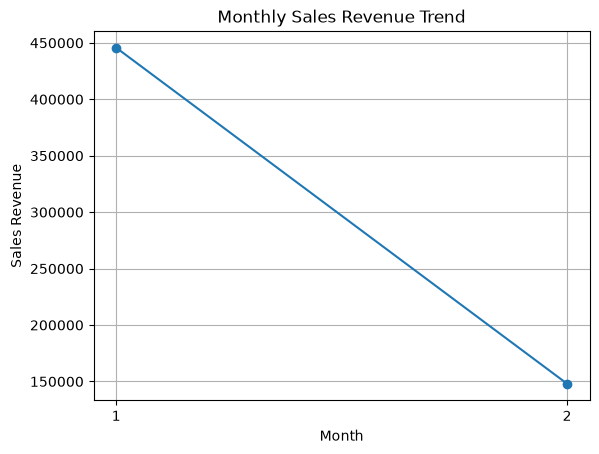

In [48]:
import matplotlib.pyplot as plt
plt.plot(monthly_sales.index, monthly_sales.values, marker='o')
plt.xlabel('Month')
plt.ylabel('Sales Revenue')
plt.title('Monthly Sales Revenue Trend')
plt.xticks(monthly_sales.index)
plt.grid(True)
plt.show()


In [47]:
category_share = category_sales / category_sales.sum()
print('Product category revenue share:')
print((category_share * 100).round(2).astype(str) + '%')


Product category revenue share:
Category
Sports         24.89%
Beauty         22.59%
Clothing       20.46%
Home           16.52%
Electronics    15.54%
Name: OrderValue, dtype: str


In [46]:
daily_sales_sorted = daily_sales.sort_index()
rolling_avg = daily_sales_sorted.rolling(window=7).mean()
print('7-day moving average sales:')
print(rolling_avg.head(10))


7-day moving average sales:
InvoiceDate
2010-12-01             NaN
2010-12-02             NaN
2010-12-03             NaN
2010-12-05             NaN
2010-12-06             NaN
2010-12-07             NaN
2010-12-08    46422.331429
2010-12-09    45550.412857
2010-12-10    47150.074286
2010-12-12    43095.854286
Name: TotalSales, dtype: float64


In [45]:
category_revenue = df_merged.groupby('Category')['OrderValue'].sum().sort_values(ascending=False)
top_category = category_revenue.index[0]
top_revenue = category_revenue.iloc[0]
print(f'The top-selling category is {top_category} with revenue of {top_revenue:,.2f}.')


The top-selling category is Sports with revenue of 147,783.07.
